<div style="
background:linear-gradient(135deg,#171922,#10131b);
border:2px solid #3ce7e7;
border-radius:22px;
padding:32px;
font-family:-apple-system,BlinkMacSystemFont,'Segoe UI',Roboto,Arial,sans-serif;
color:white;
box-shadow:0 0 18px rgba(60,231,231,.18);
">

<div style="display:flex;align-items:center;gap:14px;">
<span style="font-size:34px;">👨‍💻</span>

<div>
<div style="
font-size:34px;
font-weight:800;
color:#4ff5f5;
text-shadow:0 0 8px rgba(79,245,245,.35);
">
Aliakbar Isapour
</div>

<div style="
color:#bfbfbf;
font-size:16px;
margin-top:3px;
">
Machine Learning • Data Science • AI
</div>
</div>
</div>

<div style="
height:2px;
background:linear-gradient(90deg,#7b3ff2,#4ff5f5);
border-radius:5px;
margin:22px 0;
"></div>

<div style="
color:#d7d7d7;
font-size:16px;
line-height:1.7;
margin-bottom:25px;
">

</div>


<div style="display:flex;gap:14px;flex-wrap:wrap;">

<a href="https://github.com/isapour0"
target="_blank"
rel="noopener noreferrer"
style="
display:inline-block;
margin: 0 10px;
text-decoration:none;
background:#23283a;
color:#4ff5f5;
padding:12px 22px;
border-radius:12px;
border:1px solid #4ff5f5;
font-weight:bold;
transition:0.25s;
">
GitHub
</a>

<a href="https://www.linkedin.com/in/aliakbar-isapour-682592413"
target="_blank"
rel="noopener noreferrer"
style="
display:inline-block;
margin: 0 10px;
text-decoration:none;
background:#23283a;
color:#4ff5f5;
padding:12px 22px;
border-radius:12px;
border:1px solid #4ff5f5;
font-weight:bold;
transition:0.25s;
">
LinkedIn
</a>


</div>

</div>

### Problem
Classify small colour images into 10 classes (airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck) using a fully connected network (MLP) built with Keras.

### The CIFAR-10 dataset 
consists of 60000 32x32 colour images in 10 classes, with 6000 images per class. There are 50000 training images and 10000 test images.

The dataset is divided into five training batches and one test batch, each with 10000 images. The test batch contains exactly 1000 randomly-selected images from each class. The training batches contain the remaining images in random order, but some training batches may contain more images from one class than another. Between them, the training batches contain exactly 5000 images from each class.
Source: https://www.cs.toronto.edu/~kriz/cifar.html

### Target and metric
- Target: the class label (0-9).
- Main metric: test accuracy. The EDA section will check that the classes are balanced, which is what makes accuracy a fair first metric.

<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-left: 8px solid #00E5FF;
border-radius:18px;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">

<h2 style="color:#00E5FF;">📌 Library Imports</h2>
<hr style="border:1px solid #8A2BE2; opacity:.4;">
</div>


In [2]:
# ---- core ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path

# ---- modelSelection and metrics ----
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# ---- keras ----
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical


RANDOM_STATE = 42
tf.keras.utils.set_random_seed(RANDOM_STATE)

classes_name = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-radius:18px;
border-left: 8px solid #00E5FF;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">
    
<h2 style="color:#00E5FF;">📂 Data Loding</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">
</div>


In [4]:
DATA_DIR = Path("../data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)

paths = {name: DATA_DIR / f"{name}.npy" for name in ["X_train", "y_train", "X_test", "y_test"]}

if all(p.exists() for p in paths.values()):
    print("Loading CIFAR-10 from local .npy files...")
    X_train = np.load(paths["X_train"])
    y_train = np.load(paths["y_train"])
    X_test = np.load(paths["X_test"])
    y_test = np.load(paths["y_test"])
else:
    print("Downloading CIFAR-10 with Keras...")
    (X_train, y_train), (X_test, y_test) = cifar10.load_data()
    np.save(paths["X_train"], X_train)
    np.save(paths["y_train"], y_train)
    np.save(paths["X_test"], X_test)
    np.save(paths["y_test"], y_test)
    print("Saved to", DATA_DIR.resolve())

Loading CIFAR-10 from local .npy files...


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-left: 8px solid #00E5FF;
border-radius:18px;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">

<h2 style="color:#00E5FF;">📊 EDA</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">

<ul>
    
Questions for this section:
1. What do the images look like?
2. Are the classes balanced in the training and test sets?
3. What is the range of the pixel values?
4. Histogram of pixels in each color channel
</ul>
</div>

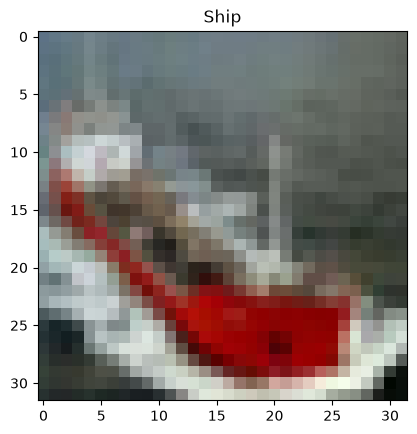

In [8]:
plt.imshow(X_train[465])
plt.title(classes_name[int(y_train[465, 0])])
plt.show()

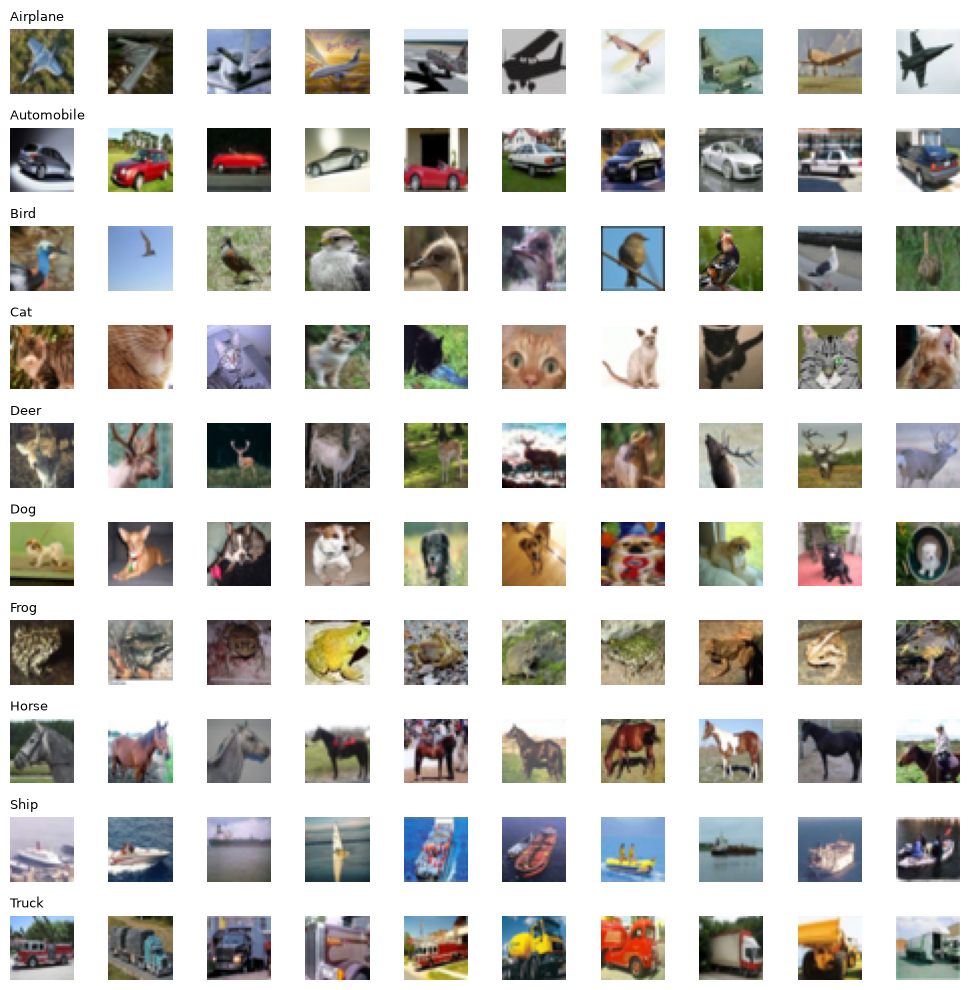

In [29]:
rng = np.random.default_rng(RANDOM_STATE)

fig, axes = plt.subplots(10, 10, figsize=(10, 10))
for k in range(10):
    idx = rng.choice(np.where(y_train.ravel() == k)[0], size=10, replace=False)
    for j, i in enumerate(idx):
        axes[k, j].imshow(X_train[i])
        axes[k, j].axis("off")
    axes[k, 0].set_title(classes_name[k], fontsize=9, loc="left")

plt.tight_layout()
plt.savefig(FIG_DIR / "samples_per_class.png", dpi=150, bbox_inches="tight")
plt.show()

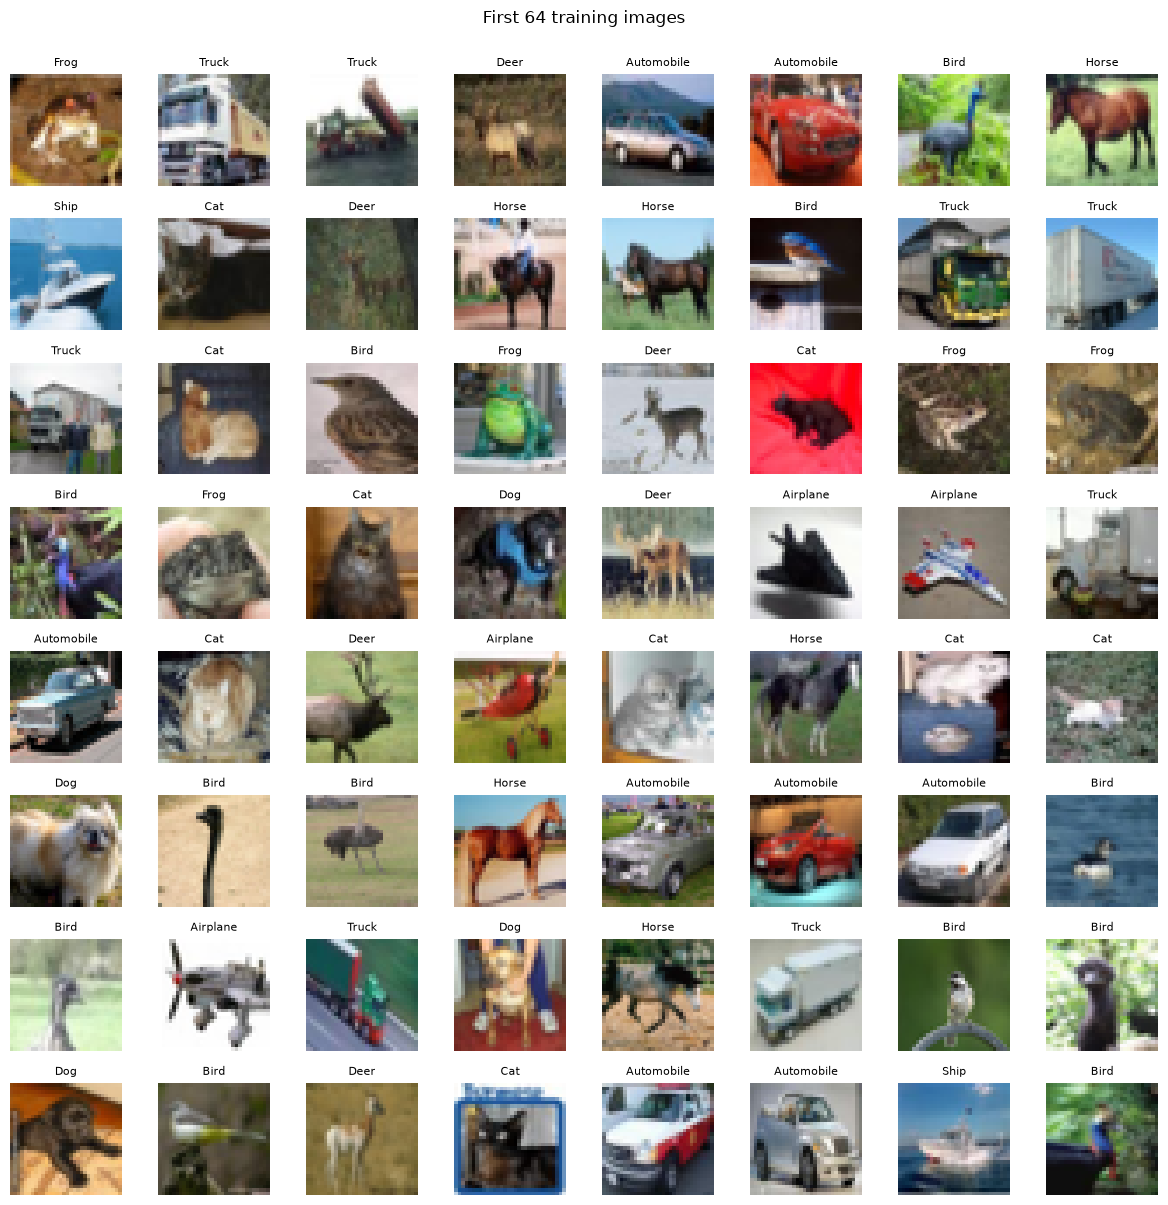

In [6]:
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(8, 8, figsize=(12, 12))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_train[i])
    ax.set_title(classes_name[y_train[i, 0]], fontsize=8)
    ax.axis("off")

plt.suptitle("First 64 training images", y=1.0)
plt.tight_layout()
plt.savefig(FIG_DIR / "sample_images.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
counts = pd.DataFrame({
    "train": pd.Series(y_train.ravel()).value_counts().sort_index(),
    "test": pd.Series(y_test.ravel()).value_counts().sort_index(),
})
counts.index = classes_name
counts

,train,test
Airplane,5000,1000
Automobile,5000,1000
Bird,5000,1000
Cat,5000,1000
Deer,5000,1000
Dog,5000,1000
Frog,5000,1000
Horse,5000,1000
Ship,5000,1000
Truck,5000,1000


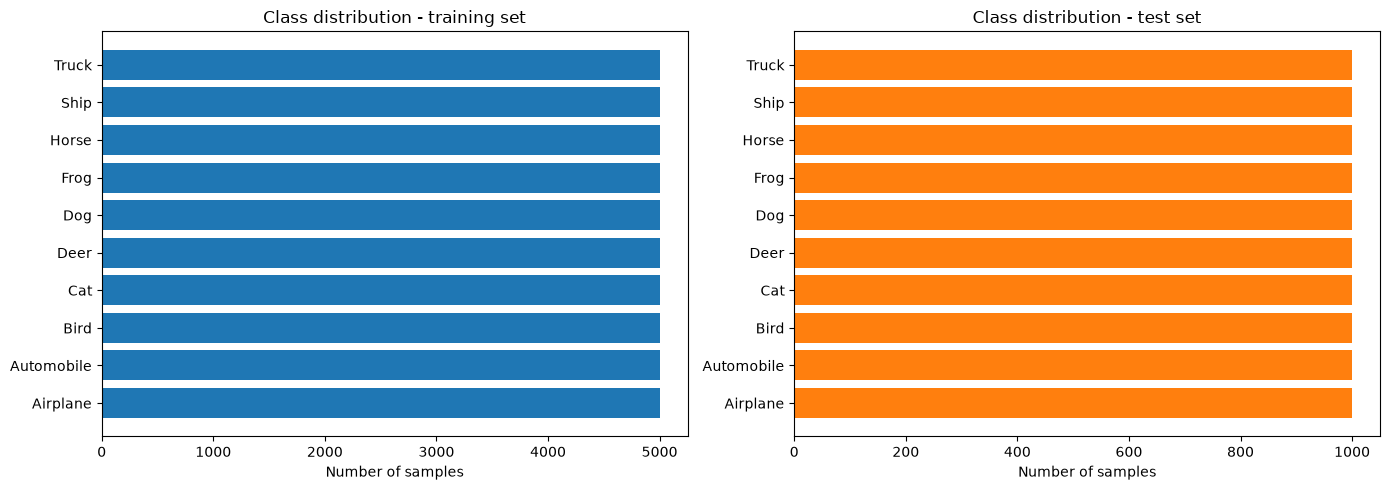

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(classes_name, counts["train"], color="tab:blue")
axes[0].set_title("Class distribution - training set")

axes[1].barh(classes_name, counts["test"], color="tab:orange")
axes[1].set_title("Class distribution - test set")

for ax in axes:
    ax.set_xlabel("Number of samples")

plt.tight_layout()
plt.savefig(FIG_DIR / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [31]:
print(f"X_train: min={X_train.min()}  max={X_train.max()}")
print(f"X_test : min={X_test.min()}  max={X_test.max()}")
print(f"y_train: min={y_train.min()}  max={y_train.max()}")
print(f"y_test : min={y_test.min()}  max={y_test.max()}")

X_train: min=0  max=255
X_test : min=0  max=255
y_train: min=0  max=9
y_test : min=0  max=9


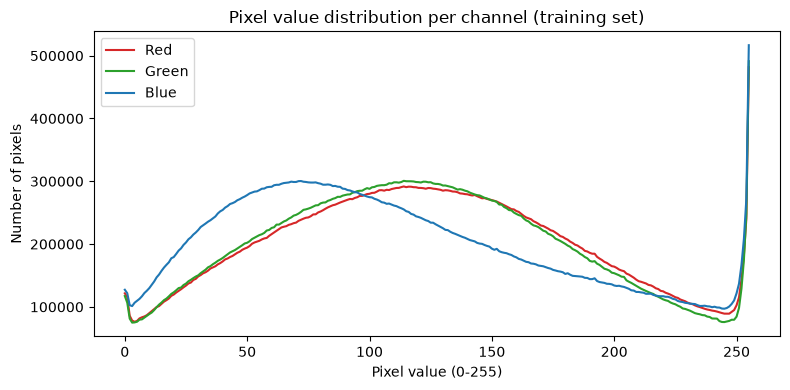

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
for c, (name, color) in enumerate(zip(["Red", "Green", "Blue"], ["tab:red", "tab:green", "tab:blue"])):
    counts_c = np.bincount(X_train[..., c].ravel(), minlength=256)
    ax.plot(counts_c, color=color, label=name)

ax.set_xlabel("Pixel value (0-255)")
ax.set_ylabel("Number of pixels")
ax.set_title("Pixel value distribution per channel (training set)")
ax.legend()
plt.tight_layout()
plt.show()

In [15]:
# Computed on the training set only (the test set must not influence preprocessing)
channel_mean = X_train.mean(axis=(0, 1, 2))
channel_std = X_train.std(axis=(0, 1, 2))
print("Mean per channel (R, G, B):", channel_mean.round(2))
print("Std  per channel (R, G, B):", channel_std.round(2))

Mean per channel (R, G, B): [125.31 122.95 113.87]
Std  per channel (R, G, B): [62.99 62.09 66.7 ]
